# Assignment 3

The goal of this assignment is to classify **CIFAR-10 images (10 classes)** using **feature extraction** with a pretrained VGG16 convolutional base.

The frozen base converts each image into a feature vector and then a small but fully connected classifier is trained on those feature.


**Sections:**
1. Data
2. Convolutional base
3. Feature extraction
4. Classifier and hyperparameter selection
5. Test results

In [45]:
import keras
import numpy as np
import matplotlib.pyplot as plt
from keras import layers, models, optimizers

In [ ]:
# Fixed seed for reproducibility
keras.utils.set_random_seed(21)

# Number of images in each batch
batch_size = 32

# 32x32 pixel images in input data
img_size = (32, 32)

## 1. Data

The **CIFAR-10 images** are loaded from directories as **32x32** images with one-hot encoded labels. 

The **50 000 training images** are split into **80/20** meaning 40 000 for training and 10 000 for validation.


The separate **10 000 test images** are only ever used for the final evaluation. 

The original **32x32** size is kept to keep feature extraction fast.

In [47]:
train_dataset, validation_dataset = keras.utils.image_dataset_from_directory(
    'dataset/train',
    batch_size=batch_size,
    image_size=img_size,
    label_mode='categorical',
    validation_split=0.2,
    subset='both',
    seed=123
)

test_dataset = keras.utils.image_dataset_from_directory(
    'dataset/test',
    batch_size=batch_size,
    image_size=img_size,
    label_mode='categorical'
)

Found 50000 files belonging to 10 classes.
Using 40000 files for training.
Using 10000 files for validation.
Found 10000 files belonging to 10 classes.


## 2. Convolutional base

VGG16 pretrained on ImageNet is loaded **without its dense top** and with a 32x32x3 input shape. Its weights are **frozen** so it acts as a fixed feature extractor and only the new classifier is trained.

In [48]:
# Loads VGG16 pretrained on ImageNet, excluding the top Dense classifier

conv_base = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(32, 32, 3)
)

# Freezes the convolutional base so its weights are not updated
conv_base.trainable = False
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## 3. Feature extraction

Each image is first scaled with **VGG16's** `preprocess_input`(the preprocessing the network was trained with) and then passed once through the frozen base.

Due to the input being only 32x32, the five pooling stages reduce the output to a `1x1x512` feature map per image. Therefore, the shapes are `(N, 1, 1, 512)`

The features are computed once for the training, validation and test sets making the training the classifier very fast.

In [49]:
def get_features_and_labels(dataset):
    all_features = []
    all_labels = []

    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images.numpy())
        features = conv_base.predict(preprocessed_images, verbose=0)
        all_features.append(features)
        all_labels.append(labels.numpy())

    return np.concatenate(all_features), np.concatenate(all_labels)




In [50]:
# Extracts the features for train (40k), validation (10k), and test (10k) sets
train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

## 4. Classifier and hyperparameter selection

Three configurations were tested when the Model was trained to find the best dense classifier head on top of the frozen VGG16 features.


1. **256 units, learning rate `1e-4`, 25 epochs:** Reached `65.50%` validation accuracy (`64.72%` test accuracy), but validation loss climbed steadily to `1.2639`, indicating overfitting.
2. **128 units, learning rate `1e-4`, 15 epochs:** Underfitted slightly, reaching `61.63%` validation accuracy (val loss: `1.1536`, test accuracy: `61.41%`).
3. **256 units, learning rate `5e-4`, 10 epochs:** Converged faster and generalized best, achieving **65.36% validation accuracy**, the lowest validation loss (**1.0730**), and **65.13% test accuracy** with minimal overfitting.

Only the final best configuration is kept and used below.


In [51]:
model = models.Sequential([
    layers.Input(shape=(1, 1, 512)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=optimizers.Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_features,
    train_labels,
    epochs=10,
    batch_size=32,
    validation_data=(val_features, val_labels),
    verbose=1
)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.4036 - loss: 3.5849 - val_accuracy: 0.5499 - val_loss: 1.3311
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5149 - loss: 1.4256 - val_accuracy: 0.5921 - val_loss: 1.1886
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5661 - loss: 1.2533 - val_accuracy: 0.6224 - val_loss: 1.1284
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5941 - loss: 1.1623 - val_accuracy: 0.6326 - val_loss: 1.0857
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6182 - loss: 1.0978 - val_accuracy: 0.6412 - val_loss: 1.0648
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6314 - loss: 1.0504 - val_accuracy: 0.6460 - val_loss: 1.0619
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6457 - loss: 1.0121 - val_accuracy: 0.6522 - val_loss: 1.0513
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6586 - loss: 0.9722 - 

### 4.1 Training curves

The plots show training and validation accuracy and loss per epochs.

The training accuracy keeps improving while validation accuracy levels off at about **65%** and the gap between the two curves shows the mild overfitting that remains.

The training was eventually stopped at **10 epochs** before validation loss started to rise.

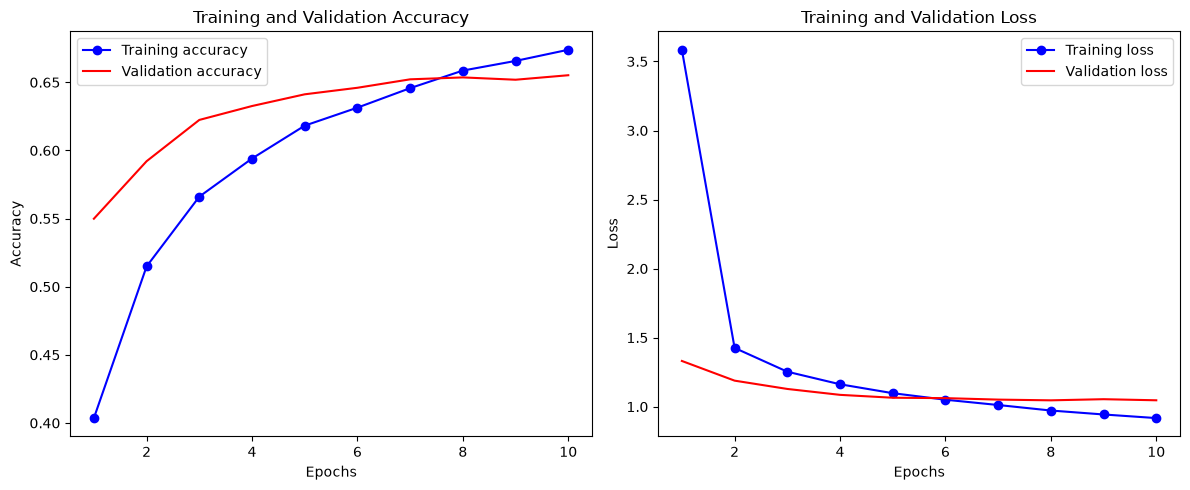

In [52]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, "bo-", label="Training accuracy")
plt.plot(epochs_range, val_acc, "r-", label="Validation accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, "bo-", label="Training loss")
plt.plot(epochs_range, val_loss, "r-", label="Validation loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 5. Test results

The selected model is evaluated once on the untouched test set.

In [53]:
test_loss, test_acc = model.evaluate(test_features, test_labels, verbose=0)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)")

Test Loss:     1.0653
Test Accuracy: 0.6516 (65.16%)


## 6. Conclusion

The model reaches a test accuracy of about **65%**, close to its validation accuracy, so it generalizes consistently. The accuracy is modest because **VGG16** was trained on much larger ImageNet images, and 32x32 inputs are shrunk to a 1x1 feature map, which loses most spatial information. 

The possible improvements are upscaling the images (e.g. to 64x64 or 96x96) before feature extraction, using data augmentation or fine-tuning the top convolutional layers.